# Distribuição de Probabilidades Contínuas

### Monstro: Golem

Autor: **Carlos Gabriel de Oliveira Campos**

Professor Dr. **Daniel Roberto Cassar**

"Na matemática, frequentemente lidamos com resultados incertos ou variáveis, como o tempo de resposta de um servidor ou a altura de uma pessoa escolhida aleatoriamente. Esses resultados não são valores fixos, mas fazem parte de um intervalo. Para modelar esse cenário, costuma-se utilizar a distribuição de probabildiades contínuas." [1, tradução própria]. Nesse contexto, uma variável contínua significa que ela pode assumir *qualquer* valor dentro de um intervalo, sendo que as probabilidades são calculadas entre um intervalo de valores, mas que a probabilidade de um único valor é 0. 

---

## Exercícios

Pesquisadores do Instituto de Sismologia modelam o tempo $X$ (em semanas) entre 
dois tremores consecutivos registrados em uma região de média atividade sísmica pela 
distribuição abaixo.

$$
f(x) = \begin{cases} 
x e^{-x} & \text{se } x > 0 \\ 
0 & \text{caso contrário} 
\end{cases}
$$

### 1. Mostre que $f(x)$ é uma pdf válida.



De acordo com [2]:
"Para $f(x)$ ser considerada uma pdf de uma variável aleatória contínua $X$ qualquer, ela deve satisfazer as duas condições abaixo":

$$
\begin{aligned}
\forall x: f(x) \geq 0 \qquad &(1) \\


\int_{-\infty}^{\infty} f(x) \, \mathrm{d}x = 1 \qquad &(2)
\end{aligned}
$$



Vamos verificar a primeira condição. Se $x \leq 0$, então $f(x) = 0$. Caso contrário, $f(x) = xe^{-x}$. Como $x > 0$ e um número positivo elevado a qualquer número real também é positivo, então $e^{-x}$ também é postivo. Portanto, $f(x)$ satisfaz a primeira condição.

Verifiquemos agora a segunda condição. A seguinte integral será calculada numericamente usando a função `quad` do módulo `scipy.integrate`. 

In [13]:
from scipy.integrate import quad
import numpy as np


def f(x):
    if x > 0:
        return x*np.exp(-x)   
    else:
        return 0 

soma_probs = quad(f, -np.inf, np.inf)[0]

print(f"Soma de todas as probabilidades: {soma_probs}")

Soma de todas as probabilidades: 0.9999999999999998


Claramente, podemos aproximar a soma para 1. Portanto, $f(x)$ é uma pdf válida.

### 2. Calcule os quatro primeiros momentos com relação à origem de $X$: $\mu'_1$, $\mu'_2$, $\mu'_3$ e $\mu'_4$.


Dado que

$$
\mu'_n = E[X^n] = \int_{-\infty}^{\infty} x^n f(x) \, dx
$$

Então o n-ésimo momento em relação à origem de $f(x)$ é dado por

$$
\mu'_n = \int_{-\infty}^{\infty} x^n x e^{-x} \, dx = \int_{-\infty}^{\infty} x^{n+1} e^{-x} \, dx = \int_{0}^{\infty} x^{n+1} e^{-x} \, dx 
$$

In [14]:
momentos = {}
for n in range(1,5):
    momentos[n] = quad(lambda x: (x**n) * f(x), 0, np.inf)[0]
for momento in momentos:
    print(f"μ'-{momento}: {momentos[momento]}")

μ'-1: 2.0
μ'-2: 6.0
μ'-3: 24.0
μ'-4: 120.00000000000001


Portanto, podemos notar que os momentos em ralação à origem de $f(x)$ seguem o fatorial de inteiros $(2! = 2, 3! = 6, 4! = 24, 5! = 120...)$.   


Acontece que $E[X]$ segue a *função Gamma*, a qual é definida como:

$$
\Gamma(\alpha) = \int_1^\infty e^{-x} x^{\alpha -1} \, \mathrm{d}x.
$$

Para $\alpha > 1$ Essa função pode ser considerada a generalização da função fatorial, de modo que para valores de $n$ inteiros positivos:

$$
\Gamma(n) = (n - 1)!
$$

Assim, ao compararmos $\mu'_n$ à função Gamma, é possível obter que

$$
\mu'_n = \int_{0}^{\infty} x^{n+1} e^{-x} \, dt = \Gamma(n + 2) = (n + 1)!
$$

O que explica o comportamento fatorial dos momentos com relação à origem de $X$.

###  3. Utilizando os resultados do item anterior, calcule $E[X]$ e $\text{Var}(X)$.


Tendo em vista que $E[X] = \mu'_1$, então $E[X] = 2$, conforme calculado no item anterior.

Pela definição:

$$
\mathrm{Var}(X) = E[X^2] - (E[X])^2
$$

Logo,a variância da pdf pode ser calculada como


$$
\mathrm{Var}(X) = \mu'_2 - (\mu'_1)^2
$$

Assim, utilizando os valores calculados no item anterior, a variância pode ser calculada como

$$
\mathrm{Var}(X) = 6 - 2^2 = 6 - 4 = 2
$$

### 4. Calcule a assimetria (terceiro momento central padronizado) de 𝑋. Com base no valor obtido, o que você pode afirmar sobre a forma da distribuição? O formato da curva corrobora esta afirmação?

Como afirma o enunciado, a assimetria pode ser calculada a partir do terceiro momento central padronizado, ou seja: 

$$
\mathrm{Assimetria} = \frac{\mu_3}{\sigma^3}
$$

Em que o n-ésimo momento central $\mu_n$ é definido como 
$$
\mu_n = E[(X - E[X])^n]
$$
E $\sigma^n$ representa a n-ésima potência do desvio padrão, isto é, a raíz quadrada da variância, já calculada anteriormente. Assim:

$$
\sigma^n = \left(\sqrt{\mathrm{Var(X)}}\right)^n
$$

Portanto: 

$$
\mathrm{Assimetria} = \frac{\mu_3}{\sigma^3} = \frac{E[(X - E[X])^3]}{\left(\sqrt{\mathrm{Var(X)}}\right)^3} = \frac{E[(X - 2)^3]}{\left(\sqrt{2}\right)^3}
$$

Em que 

$$
E[(X - 2)^3] = \int_{-\infty}^{\infty} (x -2)^3 f(x) \, dx
$$

Será calculado de acordo com o código a seguir

In [15]:
esperado = momentos[2]
mu_3 = quad(lambda x: ((x - esperado)**3) * f(x), 0, np.inf)[0]
print(f"Valor de μ-3: {mu_3}")

Valor de μ-3: 4.0


Logo,
$$
\mathrm{Assimetria} = \frac{4}{\left(\sqrt{2}\right)^3} = \frac{\left(\sqrt{2}\right)^4}{\left(\sqrt{2}\right)^3} = \sqrt{2}
$$

Portanto, uma assimetria positiva indica que a média é maior do que a mediana. Desse modo, deve haver uma longa cauda à direita, ao mesmo tempo que a maioria dos resultados estarão abaixo da média. Além disso, no caso unimodal, segue-se que $\text{Moda} < \text{Mediana} < \text{Média}$. 

Para verificar se $f(x)$ é unimodal, deve haver um único ponto de máximo global, até o qual $f(x)$ cresce e a partir dele passa a diminuir. Ou seja, deve haver um único ponto crítico real ao calcular a primeira derivada dentro do *intervalo de suporte*, ou seja, $x > 0$.

Calculando a derivada de $f(x)$:
$$
f'(x | x > 0) = \frac{\mathrm{d}}{\mathrm{d}x}[xe^{-x}] = e^{-x} -xe^{-x} = e^{-x}(1 - x)
$$

Encontrando o ponto crítico de $f'(x | x > 0) = 0$:
$$ e^{-x}(1 - x) = 0 $$

Como $e^{-x} \neq 0$:

$$ (1-x) = 0 \implies x = 1$$

Calculando a segunda derivada:

$$ f''(x) = \frac{\mathrm{d}}{\mathrm{d}x}[e^{-x}(1 - x)] = -e^{-x} -e^{-x}(1 -x) = e^{-x}(x - 1) -e^{-x} = e^{-x}(x - 2)$$

Avaliando a segunda derivada em $x=0$:
$$f''(0) = e^{0}(0 - 2) = -2$$

Logo $f''(0) < 0$ indica que $f(1)$ é um ponto de máximo - a moda!

Como vimos ao final do item 2, $E[X]$ segue a função Gamma. Entretanto, foi omitido que $f(x)$ segue uma *distribuição Gamma*! Isto é, a dsitribuição gamma é definida conforme:

$$
\gamma(x\,|\, \alpha, \beta)=\begin{cases}
\frac{1}{\beta^\alpha \Gamma(\alpha)} x^{\alpha -1} e^{-\frac{x}{\beta}} & x \geq 0\\
0 & \textrm{caso contrário}
\end{cases}
$$

Com os parâmetros $\alpha, \beta > 0$. 


Assim, se $x > 0$, $\alpha = 2$ e $\beta = 1$:
$$
\gamma(x\,|\, \alpha, \beta) = \frac{1}{1^2 \Gamma(2)} x^{2 -1} e^{-\frac{x}{1}} = xe^{-x} = f(x)
$$

Por isso, ela será plotada via python como uma distribuição gamma: `dist = stats.gamma(a=2, scale=1)`

Moda: 1.0
Mediana: 1.6783
Média: 2.0


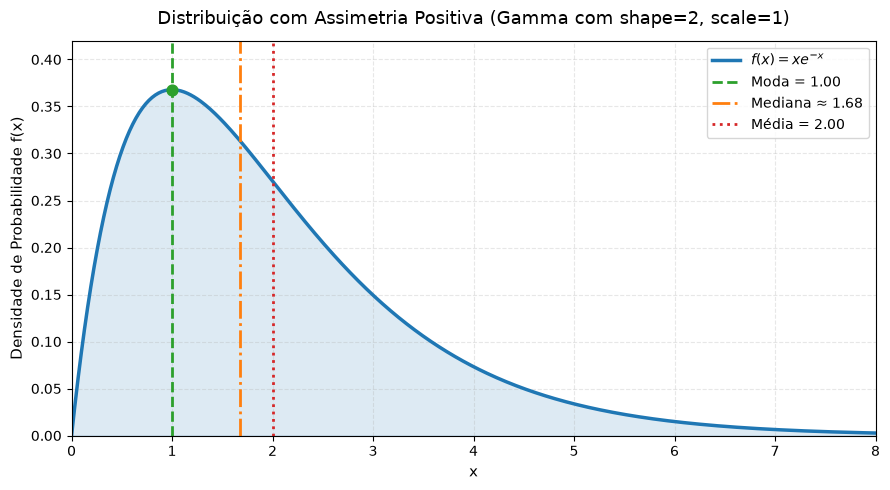

In [23]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# A distribuição é Gamma(a=2, scale=1)
# PDF: f(x) = x * exp(-x) para x > 0
dist = stats.gamma(a=2, scale=1)

from scipy.optimize import minimize_scalar

# Moda: derivada f'(x) = (1-x)e^(-x) = 0 -> x = 1
mode_val = 1.0

# Média: E[X] = a * scale = 2 * 1 = 2
mean_val = dist.mean()

# Mediana: dist.median() ou dist.ppf(0.5)
median_val = dist.median()

print(f"Moda: {mode_val}")
print(f"Mediana: {median_val:.4f}")
print(f"Média: {mean_val}")

# Gerar gráfico
x = np.linspace(0, 8, 500)
y = dist.pdf(x)

plt.figure(figsize=(9, 5))
plt.plot(x, y, label=r'$f(x) = x e^{-x}$', color='#1f77b4', lw=2.5)
plt.fill_between(x, y, alpha=0.15, color='#1f77b4')

# Linhas verticais
plt.axvline(mode_val, color='#2ca02c', linestyle='--', lw=2, label=f'Moda = {mode_val:.2f}')
plt.axvline(median_val, color='#ff7f0e', linestyle='-.', lw=2, label=f'Mediana ≈ {median_val:.2f}')
plt.axvline(mean_val, color='#d62728', linestyle=':', lw=2, label=f'Média = {mean_val:.2f}')

# Pontos de destaque no topo da curva / eixo
plt.scatter([mode_val], [dist.pdf(mode_val)], color='#2ca02c', s=60, zorder=5)

plt.title('Distribuição com Assimetria Positiva (Gamma com shape=2, scale=1)', fontsize=13, pad=12)
plt.xlabel('x', fontsize=11)
plt.ylabel('Densidade de Probabilidade f(x)', fontsize=11)
plt.xlim(0, 8)
plt.ylim(0, 0.42)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()

Confirma-se a presença da longa cauda à direita, assim como as inequações $\text{Moda} < \text{Mediana} < \text{Média}$.

Média: 2.0
Área [0, 2]: 0.5940 (59.4%)
Área [2, ∞): 0.4060 (40.6%)


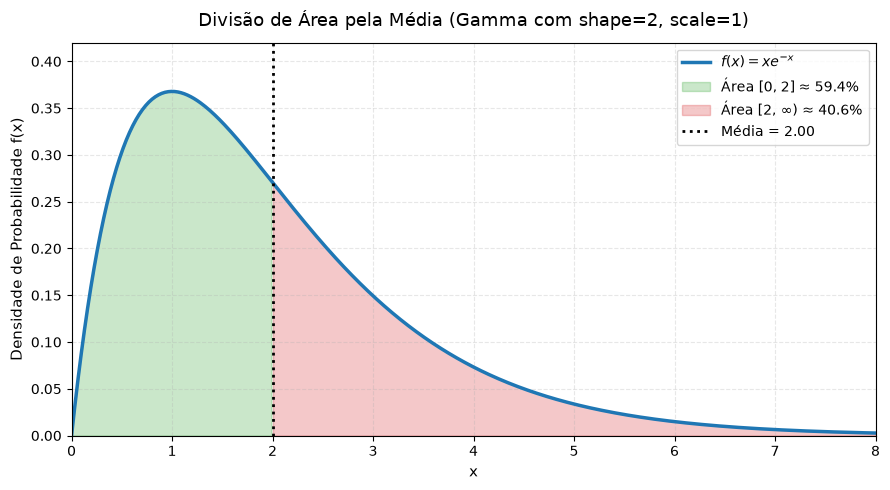

In [22]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# A distribuição é Gamma(a=2, scale=1)
# PDF: f(x) = x * exp(-x) para x > 0
dist = stats.gamma(a=2, scale=1)

# Média: E[X] = a * scale = 2 * 1 = 2
mean_val = dist.mean()

# Cálculo das áreas
area_0_to_2 = dist.cdf(mean_val)
area_2_to_inf = dist.sf(mean_val) # sf é a "survival function" (1 - cdf)

print(f"Média: {mean_val}")
print(f"Área [0, 2]: {area_0_to_2:.4f} ({area_0_to_2*100:.1f}%)")
print(f"Área [2, ∞): {area_2_to_inf:.4f} ({area_2_to_inf*100:.1f}%)")

# Gerar gráfico
x = np.linspace(0, 8, 500)
y = dist.pdf(x)

plt.figure(figsize=(9, 5))
plt.plot(x, y, label=r'$f(x) = x e^{-x}$', color='#1f77b4', lw=2.5)

# Divisão da área sob a curva
mask_left = x <= mean_val
mask_right = x >= mean_val

# Preencher área de 0 a 2
plt.fill_between(x[mask_left], y[mask_left], alpha=0.25, color='#2ca02c', 
                 label=f'Área [0, 2] ≈ {area_0_to_2*100:.1f}%')

# Preencher área de 2 ao infinito (limitado a 8 no gráfico) - CORRIGIDO AQUI
plt.fill_between(x[mask_right], y[mask_right], alpha=0.25, color='#d62728', 
                 label=rf'Área [2, $\infty$) ≈ {area_2_to_inf*100:.1f}%')

# Linha vertical da média
plt.axvline(mean_val, color='black', linestyle=':', lw=2, label=f'Média = {mean_val:.2f}') 

plt.title('Divisão de Área pela Média (Gamma com shape=2, scale=1)', fontsize=13, pad=12)
plt.xlabel('x', fontsize=11)
plt.ylabel('Densidade de Probabilidade f(x)', fontsize=11)
plt.xlim(0, 8)
plt.ylim(0, 0.42)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()

Ademais, o último gráfico nos permite visualizar mais claramente que mais da metade dos resultados estarão abaixo da média. 

## Conclusão

Destarte, o conceito da distribuição de densidade de probabilidade aplicado a distribuições de probabildiades contínuas foi de extrema utilidade, permitindo construir uma noção matemática para a modelagem de cenários em que averiguam-se variáveis contínuas. 

## Referências

[1] **Continuous Probability Distributions**. GeeksforGeeks, 25 jul. 2025. Disponível em: https://www.geeksforgeeks.org/maths/continuous-probability-distributions/. Acesso em: 3 out. 2026.

[2] CASSAR, Daniel R. Material de aula **LMA-203 7.0 - Distribuição de probabilidades contínuas**. para a disciplina de Estatística, 2026.

## Uso de IA neste trabalho

A ferramente de inteligência artificial Gemini foi utilizada para auxiliar a:

- Melhorar compreensão sobre dsitribuição de probabilidades, a função e distribuição gama;
- Plotar gráficos;
- Entender funções em python para distribuições e integrais;
- Revisar cálculos;